# 05. Tạo đặc trưng, điền dữ liệu thiếu, mã hoá, chuẩn hoá và chọn đặc trưng
Toàn bộ các bước có "học" từ dữ liệu (trung vị để điền thiếu, mã hoá theo mục tiêu, trung bình/độ lệch chuẩn để chuẩn hoá) **chỉ fit trên tập train**, sau đó áp dụng y nguyên cho val/test – tránh rò rỉ dữ liệu. Các bước được đóng gói trong lớp `BoTienXuLy` (`src/dac_trung.py`) để ứng dụng demo dùng lại đúng quy trình.

| Nhóm đặc trưng | Cách xử lý |
|---|---|
| Diện tích | log(diện tích) |
| Mặt tiền, chiều dài, đường vào, số tầng, số phòng | Điền trung vị theo (loại BĐS, tỉnh) + cột đánh dấu "bị thiếu" |
| Thời gian đăng | Số tháng kể từ 01/2019 (bắt xu hướng giá theo thời gian) |
| Tỉnh, quận, phường, đường, dự án (nhiều giá trị) | **Target encoding phân cấp** có làm trơn + out-of-fold; tần suất xuất hiện |
| Loại BĐS, vùng, hướng, pháp lý, nội thất, vị trí, nguồn (ít giá trị) | One-hot (bỏ một mức làm mốc để tránh đa cộng tuyến) |
| Toàn bộ | Chuẩn hoá z-score |

In [1]:
import sys, os, time
sys.path.append('../src')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.linear_model import Ridge, Lasso
from sklearn.ensemble import HistGradientBoostingRegressor
from dac_trung import *

pd.set_option('display.width', 160)
sns.set_theme(style='whitegrid')
FIG = '../reports/figures'
train = pd.read_parquet('../data/processed/train.parquet')
val = pd.read_parquet('../data/processed/val.parquet')
test = pd.read_parquet('../data/processed/test.parquet')
train_tm = pd.read_parquet('../data/processed/train_tang_mau.parquet')
y_tr, y_va = np.log(train['gia_vnd']), np.log(val['gia_vnd'])
print('train', train.shape, '| val', val.shape, '| test', test.shape, '| train tăng mẫu', train_tm.shape)

def danh_gia(p, y):
    return {'RMSE (log)': float(np.sqrt(np.mean((p - y) ** 2))), 'R²': float(1 - np.mean((p - y) ** 2) / np.var(y)),
            'MAPE (%)': float(np.mean(np.abs(np.exp(p - y) - 1)) * 100)}

train (604466, 34) | val (129529, 34) | test (129529, 34) | train tăng mẫu (738661, 33)


## 1. Đặc trưng tạo thêm từ dữ liệu gốc

In [2]:
co_ban = dac_trung_co_ban(train)
co_ban.describe().T[['mean', 'std', 'min', '50%', 'max']].round(2)

,mean,std,min,50%,max
log_dien_tich,4.52,0.89,2.3,4.37,9.21
mat_tien_m,7.49,7.67,1.0,5.00,100.00
chieu_dai_m,22.85,19.44,1.0,18.00,300.00
duong_vao_m,9.04,8.73,0.5,6.00,100.00
so_tang,2.34,2.40,0.0,2.00,50.00
so_phong_ngu,2.60,2.65,0.0,3.00,30.00
so_phong_tam,2.25,2.62,0.0,2.00,30.00
thang_tu_2019,75.77,15.35,7.1,80.12,83.94
thieu_mat_tien_m,0.43,0.49,0.0,0.00,1.00
thieu_chieu_dai_m,0.88,0.32,0.0,1.00,1.00


## 2. Điền dữ liệu thiếu – so sánh 3 chiến lược
Tỉ lệ thiếu của các cột số còn rất cao (đường vào ~75%, chiều dài ~90%). Thiếu ở đây **không ngẫu nhiên**: ví dụ tin không ghi đường vào thường là nhà trong ngõ nhỏ, căn hộ không có mặt tiền. So sánh trên tập validation bằng cùng một mô hình Ridge:
- A: điền trung vị toàn bộ
- B: điền trung vị theo nhóm (loại BĐS, tỉnh)
- C: như B + thêm cột đánh dấu "bị thiếu" (để mô hình học được chính việc thiếu mang thông tin)

In [3]:
print('Tỉ lệ thiếu trên tập train (%):', (train[COT_SO].isna().mean() * 100).round(1).to_dict())
bo_tam = BoTienXuLy()
X_c = bo_tam.fit_transform(train, np.log(train['gia_m2']))
X_c_va = bo_tam.transform(val)
cot_thieu = [c for c in X_c.columns if c.startswith('thieu_') and c != 'thieu_quan']

def bien_the(X, df, cach):
    X = X.copy()
    tho = dac_trung_co_ban(df)
    for c in COT_SO:
        if cach == 'A':
            gia_tri = tho[c].fillna(bo_tam.trung_vi_chung[c])
            X[c] = ((gia_tri - bo_tam.tb[c]) / bo_tam.dl[c]).astype(np.float32)
    return X.drop(columns=cot_thieu) if cach in ('A', 'B') else X

kq = {}
for cach, ten in [('A', 'A. Trung vị toàn bộ'), ('B', 'B. Trung vị theo nhóm'), ('C', 'C. Trung vị theo nhóm + cột đánh dấu thiếu')]:
    m = Ridge(alpha=1.0).fit(bien_the(X_c, train, cach), y_tr)
    kq[ten] = danh_gia(m.predict(bien_the(X_c_va, val, cach)), y_va)
pd.DataFrame(kq).T.round(4)

Tỉ lệ thiếu trên tập train (%): {'mat_tien_m': 42.7, 'chieu_dai_m': 88.3, 'duong_vao_m': 76.0, 'so_tang': 42.6, 'so_phong_ngu': 20.1, 'so_phong_tam': 30.9}


,RMSE (log),R²,MAPE (%)
A. Trung vị toàn bộ,0.5099,0.7797,42.6910
B. Trung vị theo nhóm,0.5102,0.7795,42.6808
C. Trung vị theo nhóm + cột đánh dấu thiếu,0.5043,0.7845,42.1601


## 3. Target encoding cho cột nhiều giá trị và vấn đề rò rỉ dữ liệu
Quận/phường/đường/dự án có hàng nghìn giá trị, one-hot sẽ tạo hàng nghìn cột thưa. Thay mỗi giá trị bằng **trung bình log(giá/m²)** của nó, làm trơn về mức của cấp cha để nhóm ít mẫu không bị nhiễu:

$TE(\text{phường}) = \dfrac{n \cdot \bar y_{\text{phường}} + m \cdot TE(\text{quận})}{n + m}$, $m$ chọn theo validation (mục 3b); quận làm trơn về tỉnh, tỉnh làm trơn về trung bình chung.

Nếu tính trung bình trên chính các dòng train rồi dùng làm đặc trưng cho chính các dòng đó, mỗi dòng "nhìn thấy" giá của chính nó → mô hình học thuộc. Vì vậy trên tập train dùng **out-of-fold (5 fold)**: giá trị mã hoá của mỗi dòng được tính từ 4 fold còn lại. Thí nghiệm dưới đây cho thấy sự khác biệt:

In [4]:
mau = train.sample(200000, random_state=1)
y_mau = np.log(mau['gia_vnd'])
kq = {}
for m_lt in [1, 20]:
    bo_oof = BoTienXuLy(m_lam_tron=m_lt)
    X_oof = bo_oof.fit_transform(mau, np.log(mau['gia_m2']))
    X_ro_ri = bo_oof.transform(mau)
    X_va_oof = bo_oof.transform(val)
    for ten, Xh in [('tính trên chính tập train (rò rỉ)', X_ro_ri), ('out-of-fold (đúng)', X_oof)]:
        mh = HistGradientBoostingRegressor(max_iter=300, random_state=42).fit(Xh, y_mau)
        a, b = danh_gia(mh.predict(Xh), y_mau), danh_gia(mh.predict(X_va_oof), y_va)
        kq[f'm = {m_lt:>2} | {ten}'] = {'RMSE train': a['RMSE (log)'], 'RMSE validation': b['RMSE (log)'], 'Chênh lệch val - train': b['RMSE (log)'] - a['RMSE (log)']}
pd.DataFrame(kq).T.round(4)

,RMSE train,RMSE validation,Chênh lệch val - train
m = 1 | tính trên chính tập train (rò rỉ),0.3816,0.4292,0.0476
m = 1 | out-of-fold (đúng),0.4064,0.4262,0.0198
m = 20 | tính trên chính tập train (rò rỉ),0.4026,0.4310,0.0284
m = 20 | out-of-fold (đúng),0.4134,0.4337,0.0203


**Nhận xét:** khi tính mã hoá trên chính tập train, sai số train thấp hơn hẳn sai số validation (mô hình được "nhắc bài"), đặc biệt khi không làm trơn (m = 1) – lúc đó mỗi phường/đường ít tin gần như mang đúng giá của chính căn nhà. Out-of-fold cho sai số train sát với sai số thật và cho kết quả validation tốt hơn khi m nhỏ. Dự án dùng out-of-fold.

### 3b. Chọn mức làm trơn m theo validation (mã hoá out-of-fold)

In [5]:
chon_m = {}
for m_lt in [1, 3, 5, 10, 20, 50]:
    bo_m = BoTienXuLy(m_lam_tron=m_lt)
    Xm, Xm_va = bo_m.fit_transform(mau, np.log(mau['gia_m2'])), bo_m.transform(val)
    hgb = HistGradientBoostingRegressor(max_iter=300, random_state=42).fit(Xm, y_mau)
    rid = Ridge(alpha=1.0).fit(Xm, y_mau)
    chon_m[m_lt] = {'RMSE val - HistGradientBoosting': danh_gia(hgb.predict(Xm_va), y_va)['RMSE (log)'],
                    'RMSE val - Ridge': danh_gia(rid.predict(Xm_va), y_va)['RMSE (log)']}
chon_m = pd.DataFrame(chon_m).T.rename_axis('m')
M_TOT = int(chon_m.mean(axis=1).idxmin())
print('Chọn m =', M_TOT)
chon_m.round(4)

Chọn m = 1


,RMSE val - HistGradientBoosting,RMSE val - Ridge
m,,
1,0.4262,0.5015
3,0.4274,0.5035
5,0.4288,0.5054
10,0.4306,0.5092
20,0.4337,0.5144
50,0.4382,0.5238


In [6]:
vd = train[['tinh', 'quan_huyen', 'phuong_xa']].head(8).copy()
vd[['te_tinh', 'te_quan', 'te_phuong']] = X_c[['te_tinh', 'te_quan', 'te_phuong']].head(8).values * bo_tam.dl[['te_tinh', 'te_quan', 'te_phuong']].values + bo_tam.tb[['te_tinh', 'te_quan', 'te_phuong']].values
vd['giá/m² ước theo phường (triệu)'] = (np.exp(vd['te_phuong']) / 1e6).round(1)
vd

,tinh,quan_huyen,phuong_xa,te_tinh,te_quan,te_phuong,giá/m² ước theo phường (triệu)
0,Hồ Chí Minh,Tân Phú,Tân Sơn Nhì,18.226443,18.495719,18.653867,126.3
1,Hồ Chí Minh,Quận 6,Phường 13,18.230361,18.472586,18.559149,114.9
2,Đà Nẵng,Sơn Trà,Mân Thái,18.054334,18.573048,18.479016,106.0
3,Tây Ninh,Đức Hòa,An Ninh Đông,16.250952,16.525355,16.294490,11.9
4,Hồ Chí Minh,Quận 6,None,18.228056,18.477726,18.477726,105.9
5,Hồ Chí Minh,Bình Tân,None,18.225919,18.289781,18.289781,87.7
6,Hà Nội,Đan Phượng,Tân Hội,18.818727,18.687033,18.910115,163.1
7,Hồ Chí Minh,None,None,18.230361,18.230361,18.230361,82.7


## 4. Fit bộ tiền xử lý trên toàn bộ tập train

In [7]:
t = time.time()
bo = BoTienXuLy(m_lam_tron=M_TOT)
X_tr = bo.fit_transform(train, np.log(train['gia_m2']))
X_va, X_te = bo.transform(val), bo.transform(test)
print(f'{time.time() - t:.0f} giây | X_train {X_tr.shape} | X_val {X_va.shape} | X_test {X_te.shape} | ô thiếu còn lại: {int(X_tr.isna().sum().sum() + X_va.isna().sum().sum() + X_te.isna().sum().sum())}')
print('Kiểm tra chuẩn hoá trên train: trung bình ~', round(float(X_tr.mean().abs().max()), 4), '| độ lệch chuẩn ~', X_tr.std().round(3).unique()[:3])

11 giây | X_train (604466, 55) | X_val (129529, 55) | X_test (129529, 55) | ô thiếu còn lại: 0


Kiểm tra chuẩn hoá trên train: trung bình ~ 0.0 | độ lệch chuẩn ~ [1.]


## 5. Chọn đặc trưng
1. Bỏ đặc trưng gần như hằng số (> 99,5% dòng cùng một giá trị)
2. Bỏ một trong hai đặc trưng tương quan quá cao với nhau (|r| > 0,95). **Không áp dụng cho 5 cột target encoding** tỉnh → quận → phường → đường → dự án: chúng cố ý lồng nhau theo cấp, cột cấp dưới chỉ khác cấp trên ở những dòng có thông tin chi tiết hơn – chính phần khác biệt đó mang giá trị dự đoán (kiểm chứng ở bước 4)
3. Lasso (phạt L1) trên tập train: đặc trưng có hệ số bằng 0 bị loại
4. Kiểm chứng bằng tập validation: bộ đặc trưng đã chọn không được kém hơn dùng toàn bộ

In [8]:
ti_le_mode = X_tr.apply(lambda c: c.round(4).value_counts(normalize=True).iloc[0])
gan_hang_so = list(ti_le_mode[ti_le_mode > 0.995].index)
print('1) Gần như hằng số:', gan_hang_so)
con = [c for c in X_tr.columns if c not in gan_hang_so]
xet = [c for c in con if not c.startswith('te_')]
tq = X_tr[xet].sample(200000, random_state=2).corr().abs()
tq_y = X_tr[xet].corrwith(y_tr).abs()
bo_tq = []
for i, a in enumerate(xet):
    for b in xet[i + 1:]:
        if tq.loc[a, b] > 0.95 and a not in bo_tq and b not in bo_tq:
            bo_tq.append(b if tq_y[a] >= tq_y[b] else a)
            print(f'   |r({a}, {b})| = {tq.loc[a, b]:.3f} -> bỏ {bo_tq[-1]}')
print('2) Tương quan quá cao:', bo_tq)
con = [c for c in con if c not in bo_tq]
idx = X_tr.sample(200000, random_state=3).index
lasso = Lasso(alpha=0.002, max_iter=5000).fit(X_tr.loc[idx, con], y_tr.loc[idx])
he_so = pd.Series(lasso.coef_, index=con)
bo_lasso = list(he_so[he_so.abs() < 1e-6].index)
print('3) Lasso cho hệ số = 0:', bo_lasso)
bo.cot_chon = [c for c in con if c not in bo_lasso]
print(f'=> Giữ {len(bo.cot_chon)} / {X_tr.shape[1]} đặc trưng')

1) Gần như hằng số: ['phap_ly=Hợp đồng mua bán', 'phap_ly=Đang chờ sổ', 'phap_ly=Khác', 'noi_that=Không / thô']


   |r(thang_tu_2019, nguon=3)| = 0.968 -> bỏ nguon=3
   |r(loai_doan, ngay_uoc_luong)| = 0.982 -> bỏ ngay_uoc_luong
   |r(loai_doan, nguon=5)| = 1.000 -> bỏ nguon=5
2) Tương quan quá cao: ['nguon=3', 'ngay_uoc_luong', 'nguon=5']


3) Lasso cho hệ số = 0: ['thieu_so_tang', 'phap_ly=Có sổ', 'noi_that=Đầy đủ', 'nguon=2']
=> Giữ 44 / 55 đặc trưng


In [9]:
idx = X_tr.sample(200000, random_state=4).index
kiem_chung = {}
for ten, cot in [('Toàn bộ đặc trưng', list(X_tr.columns)), ('Đã chọn', bo.cot_chon),
                 ('Đã chọn nhưng bỏ thêm te_quan, te_phuong, te_duong (lọc dây chuyền)', [c for c in bo.cot_chon if c not in ('te_quan', 'te_phuong', 'te_duong')])]:
    hgb = HistGradientBoostingRegressor(max_iter=300, random_state=42).fit(X_tr.loc[idx, cot], y_tr.loc[idx])
    rid = Ridge(alpha=1.0).fit(X_tr.loc[idx, cot], y_tr.loc[idx])
    kiem_chung[ten] = {'Số đặc trưng': len(cot), 'RMSE val - HistGradientBoosting': danh_gia(hgb.predict(X_va[cot]), y_va)['RMSE (log)'],
                       'RMSE val - Ridge': danh_gia(rid.predict(X_va[cot]), y_va)['RMSE (log)']}
pd.DataFrame(kiem_chung).T.round(4)

,Số đặc trưng,RMSE val - HistGradientBoosting,RMSE val - Ridge
Toàn bộ đặc trưng,55.0,0.4203,0.4953
Đã chọn,44.0,0.4223,0.4954
"Đã chọn nhưng bỏ thêm te_quan, te_phuong, te_duong (lọc dây chuyền)",41.0,0.4562,0.5365


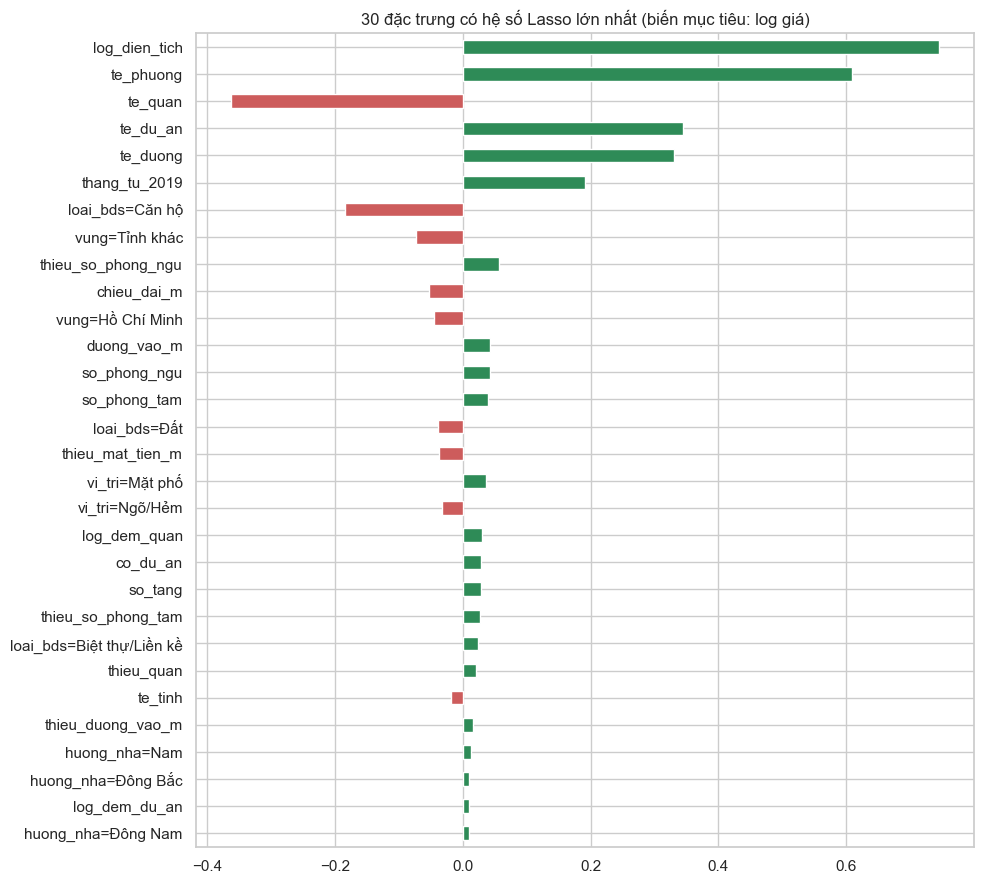

In [10]:
fig, ax = plt.subplots(figsize=(10, 9))
he_so[bo.cot_chon].sort_values(key=abs).tail(30).plot(kind='barh', ax=ax, color=np.where(he_so[bo.cot_chon].sort_values(key=abs).tail(30) > 0, 'seagreen', 'indianred'))
ax.set_title('30 đặc trưng có hệ số Lasso lớn nhất (biến mục tiêu: log giá)')
plt.tight_layout(); plt.savefig(f'{FIG}/05_he_so_lasso.png', dpi=120); plt.show()

## 6. Lưu dữ liệu đặc trưng và bộ tiền xử lý

In [11]:
NHOM = ['loai_bds', 'vung', 'phan_khuc', 'tinh', 'nguon']
def luu(X, df, ten, trong_so=None):
    out = X[bo.cot_chon].copy()
    out['y'] = np.log(df['gia_vnd']).values.astype(np.float32)
    out['trong_so'] = (trong_so if trong_so is not None else np.ones(len(df))).astype(np.float32)
    for c in NHOM:
        out['_' + c] = df[c].astype(str).values
    out.reset_index(drop=True).to_parquet(f'../data/processed/dac_trung_{ten}.parquet', index=False)
    print(ten, out.shape)

luu(X_tr, train, 'train', train['trong_so'].values)
luu(X_va, val, 'val')
luu(X_te, test, 'test')
X_tm = bo.transform(train_tm)
luu(X_tm, train_tm, 'train_tang_mau')
os.makedirs('../models', exist_ok=True)
joblib.dump(bo, '../models/bo_tien_xu_ly.joblib')
print('Đã lưu models/bo_tien_xu_ly.joblib -', round(os.path.getsize('../models/bo_tien_xu_ly.joblib') / 1e6, 1), 'MB')

train (604466, 51)


val (129529, 51)


test (129529, 51)


train_tang_mau (738661, 51)
Đã lưu models/bo_tien_xu_ly.joblib - 1.6 MB
